# 05 Entraînement sur tout le train (modèle retenu)

Le gain des 1 000 images (notebook 04) pousse à prendre **tout le train** : les 149 images corrigées et les 11 336 autres images 150 DPI, avec leurs masques PRMI aux fentes comblées (notebook A2). C'est le **modèle retenu** (`unet_effb0_tout`), évalué sur le test au notebook 07.

**L'essentiel** : nouveau gain, plus faible. Sur le grand val, Dice par image de 0,684 contre 0,668 (373 images meilleures sur 568) et 70 % des racines trouvées contre 67 %. Les rendements décroissent : chaque multiplication du nombre d'images rapporte moins.

Ce qui change par rapport au notebook 04 : 11 485 images au lieu de 1 000 ; masques comblés ; 596 carrés par époque au lieu de 298 (sinon chaque image ne serait vue qu'environ 4 fois), 150 époques au plus. Plusieurs changements à la fois : on cherche une configuration qui marche, pas l'effet de chacun.

Évaluation : val corrigé (arrêt précoce) et **grand val**, 1 000 images du val officiel notées contre les masques PRMI comblés. Plus stable (568 images avec racine), mais sa référence est en rectangles, et sa longueur peu fiable (branches parasites du squelette, environ +14 %).

Pratique : environ 3 h ; images gardées en entiers 8 bits et masques compressés (environ 4 Go) ; fermer les autres noyaux Jupyter ; clé branchée.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from prmi import viz
from prmi.dataset import VAL_LARGE, RootCrops, draw_extra, load_extra, load_lot, population, to_display, work_mask
from prmi.diagnostic import overlay_mask
from prmi.train import compare_runs, load_run, predict, run_exists, score_run, summarize, train, train_eval_items

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

SCALE = 2
CROPS_PER_EPOCH = 596                      # notebook 04 : 298
EPOCHS = 150
CLDICE = 0.0                               # 0,5 pour ajouter clDice à la perte
NAME = 'unet_effb0_tout' + ('_cldice' if CLDICE else '')
BASE = 'unet_effb0_1000'                   # notebook 04
OTHERS = ['unet_effb0_s2_aug', 'unet_effb0_s2_aug_origine']   # notebook 03 et essai E1
N_VAL_LARGE = 1000

## 1. Données

In [2]:
rows = population('train')
print(len(rows), 'images hors lot QuPath,', int(rows['has_root'].sum()), 'avec racine,', rows['tube_id'].nunique(), 'tubes')
print(rows['group'].value_counts().to_dict())

clean = load_lot('train', SCALE)                                       # 149 images, masques corrigés
train_items = clean + load_extra(rows, SCALE, compact=True)            # masques d'origine comblés, environ 3 min
val_items = load_lot('val', SCALE)                                     # masques corrigés
val_large = draw_extra(N_VAL_LARGE, path=VAL_LARGE, split='val')       # grand val (relu)
print('train', len(train_items), 'images, dont', sum(bool(work_mask(it).any()) for it in train_items), 'avec racine')

11336 images hors lot QuPath, 6397 avec racine, 28 tubes
{'150 BAZ 2015': 6584, '150 BAZ 2016': 4147, '150 CZ 2016': 605}
train 11485 images, dont 6476 avec racine


Carrés tels que le modèle les recevra : image tirée parmi toutes, position et augmentation au hasard.

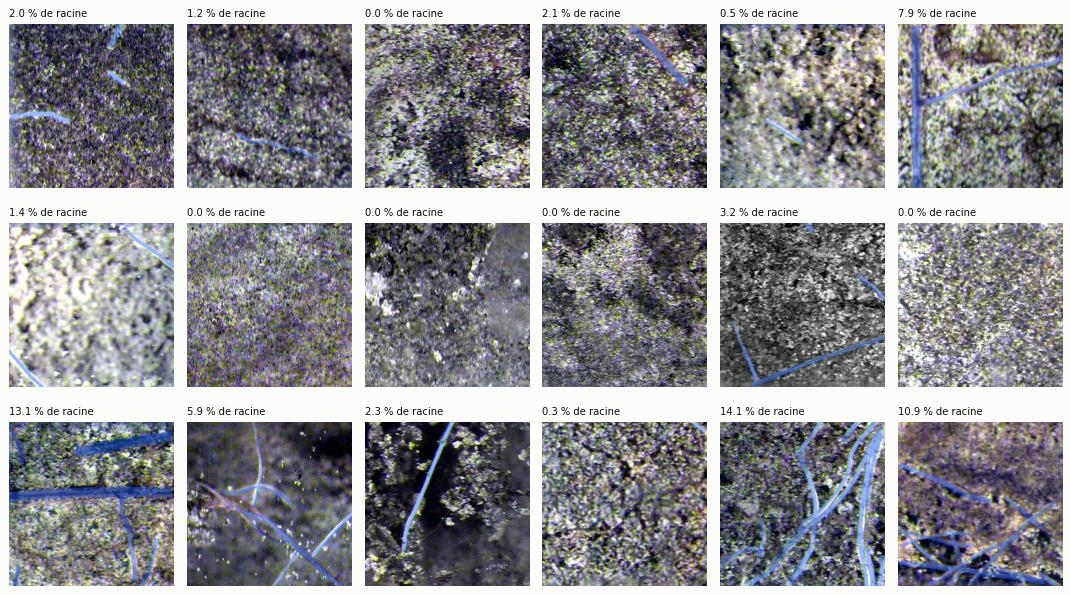

In [3]:
crops = RootCrops(train_items, seed=1, augment=True, crops_per_epoch=CROPS_PER_EPOCH)
pairs = [crops[i] for i in range(18)]
images = [overlay_mask(to_display(x), y[0].numpy() > 0) for x, y in pairs]
viz.image_grid(images, [f'{y.mean() * 100:.1f} % de racine' for _, y in pairs], ncols=6);

## 2. Entraînement

Environ 3 h (un peu plus avec clDice). Si l'entraînement existe déjà sous ce nom, il n'est pas relancé. En cas d'arrêt manuel, passer à la cellule suivante.

In [4]:
if run_exists(NAME):
    print('Entraînement déjà présent, relecture de', NAME)
else:
    train(train_items, val_items, NAME, epochs=EPOCHS, patience=20, augment=True, crops_per_epoch=CROPS_PER_EPOCH,
          train_eval=train_eval_items(clean), cldice=CLDICE)   # Dice train : mêmes 44 images corrigées que la référence

Entraînement déjà présent, relecture de unet_effb0_tout


,epoch,lr,lr_encoder,train_loss,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice,val_loss,seconds
80,81,0.000448,0.000045,0.207893,0.74194,0.733533,0.77028,0.87619,39,0.137114,0.466667,0.823768,0.862676,0.100663,77.179191


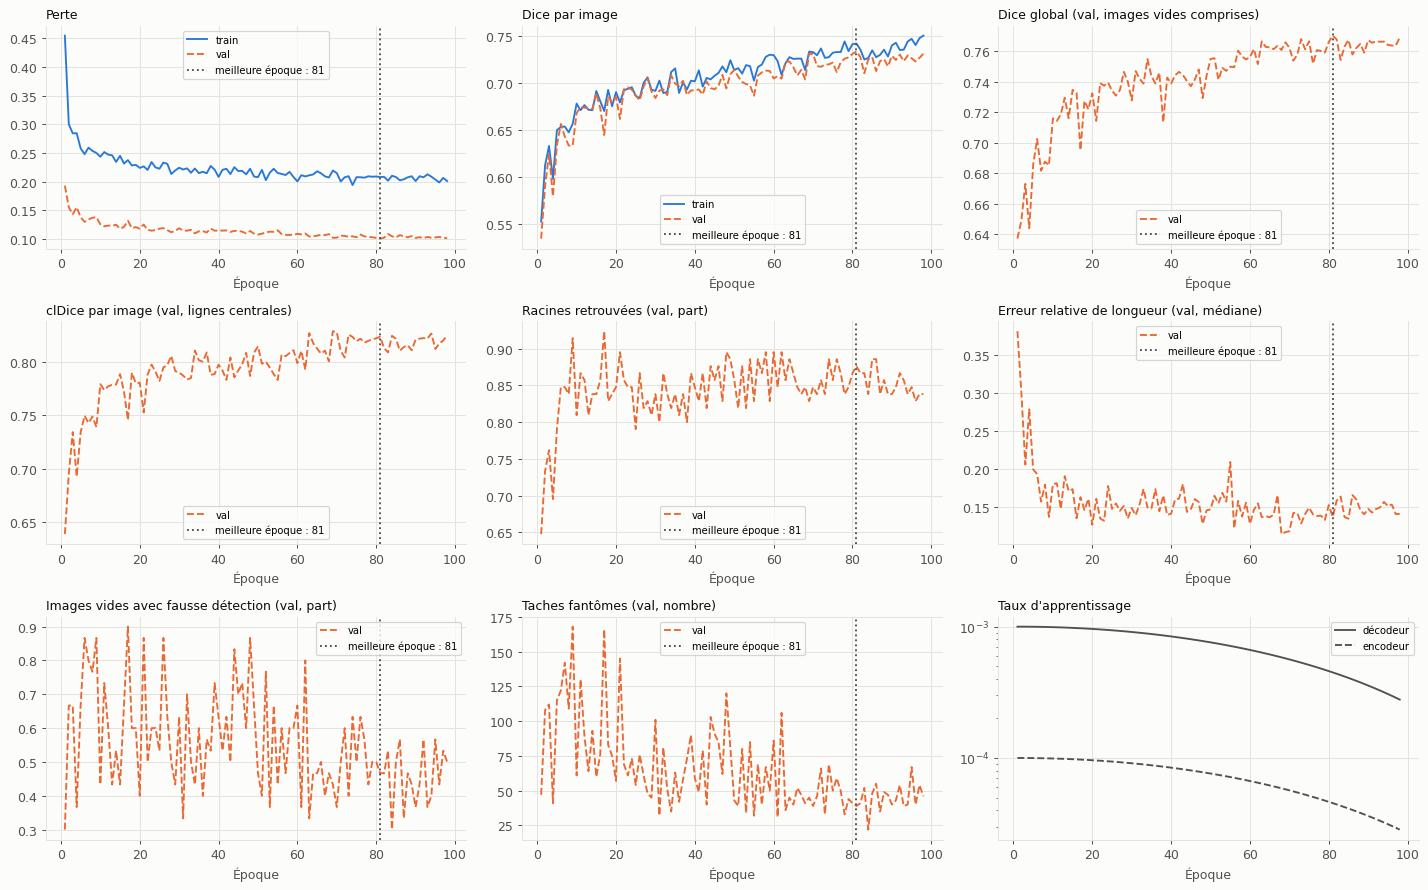

In [5]:
model, history, best_epoch, per_image = load_run(NAME)
device = next(model.parameters()).device
viz.plot_history(history, best_epoch);
history.loc[history['epoch'] == best_epoch]

## 3. Val corrigé : comparaison avec le notebook 04

Image par image sur les 44 images avec racine (écart = tout le train moins 1 000 images). Pour l'erreur de longueur, un écart négatif est un progrès.

In [6]:
rows_cmp = {}
for metric in ['dice', 'cldice', 'length_err']:
    summary, paired, _ = compare_runs(BASE, NAME, metric)
    rows_cmp[metric] = paired
display(summary.round(3))
pd.DataFrame(rows_cmp).T.round(4)

,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice
unet_effb0_1000,0.721,0.762,0.829,34.0,0.119,0.367,0.819,0.857
unet_effb0_tout,0.734,0.770,0.876,39.0,0.137,0.467,0.824,0.863


,images,écart moyen,écart médian,b meilleur,b moins bon,p (Wilcoxon)
dice,44.0,0.0128,0.0088,28.0,16.0,0.1475
cldice,44.0,0.0045,0.0005,22.0,21.0,0.8374
length_err,44.0,-0.0233,-0.0033,23.0,21.0,0.7683


## 4. Grand val (masques PRMI comblés)

Chaque modèle est évalué une fois sur les 1 000 images (environ 2 min par modèle, lues sur la clé), puis le résultat est relu. Le graphique résume la progression des essais.

In [8]:
runs = OTHERS + [BASE, NAME]
large = {n: score_run(n, val_large) for n in runs}
display(pd.DataFrame({n: summarize(t) for n, t in large.items()}).T.round(3))

rows_cmp = {}
for metric in ['dice', 'cldice', 'length_err']:
    rows_cmp[metric] = compare_runs(BASE, NAME, metric, 'val_large_comble_images.csv')[1]
pd.DataFrame(rows_cmp).T.round(4)

,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice
unet_effb0_s2_aug,0.645,0.701,0.641,762.0,0.221,0.451,0.740,0.780
unet_effb0_s2_aug_origine,0.639,0.695,0.608,588.0,0.274,0.391,0.733,0.778
unet_effb0_1000,0.668,0.716,0.667,690.0,0.221,0.391,0.768,0.800
unet_effb0_tout,0.684,0.721,0.698,801.0,0.198,0.470,0.781,0.801


,images,écart moyen,écart médian,b meilleur,b moins bon,p (Wilcoxon)
dice,568.0,0.0160,0.0086,373.0,188.0,0.0
cldice,568.0,0.0123,0.0035,322.0,239.0,0.0
length_err,568.0,-0.0129,-0.0133,351.0,204.0,0.0


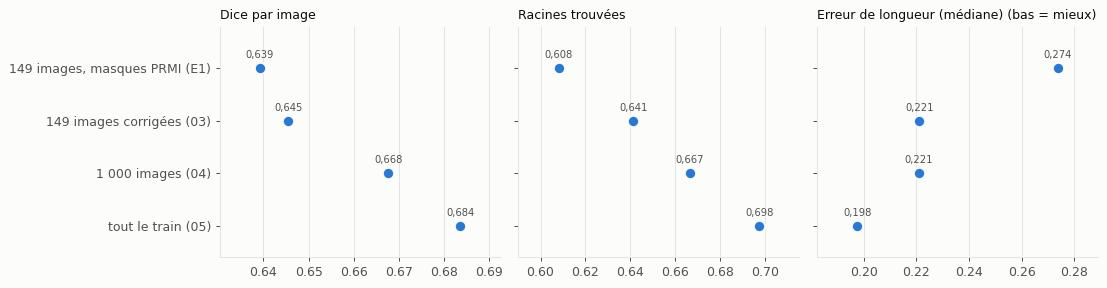

In [4]:
labels = {'unet_effb0_s2_aug_origine': '149 images, masques PRMI (E1)', 'unet_effb0_s2_aug': '149 images corrigées (03)',
          'unet_effb0_1000': '1 000 images (04)', NAME: 'tout le train (05)'}
fig = viz.plot_runs(pd.DataFrame({labels[n]: summarize(large[n]) for n in labels}).T, ['dice', 'roots_found', 'length_err'])
viz.save(fig, '05_progression_grand_val.png')

## 5. Images

Val corrigé au curseur : référence à gauche, prédiction à droite, du plus bas Dice au plus haut, images sans racine à la fin.

In [ ]:
preds = {it['name']: predict(model, it, device) for it in val_items}
viz.browse_predictions(val_items, preds, per_image)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…

## 6. À retenir

- **Gain confirmé sur le grand val** : +0,016 de Dice par image (p < 0,001), plus faible que celui des 1 000 images (+0,023) : rendements décroissants.
- **Sur le val corrigé, gain non significatif** (+0,013, p = 0,15) : 44 images avec racine ne suffisent pas à trancher des écarts de cette taille.
- **Plus de racines trouvées** (88 % sur le val, 70 % sur le grand val), au prix d'un peu plus de fausses détections (47 % des images vides touchées).
- **Le classement des essais** (graphique) résume le projet : ajouter des images, même mal annotées, rapporte plus que corriger les masques d'un petit lot.